In [1]:
from notebook_cache import NotebookCache

# results and prints live on disk, so they survive kernel restarts; one folder per notebook
cache = NotebookCache('../cache/uva')

# UVA, simplest form, built forward (cache)

One transformer reads the past frames, fills in the future frames _and_ the next actions; at run time only the action half is used. Same data, split and eval seeds as `act_byname.ipynb`.

### step 0 — the data, as in ACT


In [2]:
from pathlib import Path

import numpy as np
from lerobot.datasets.lerobot_dataset import LeRobotDataset
from numpy.typing import NDArray

np.set_printoptions(precision=3, suppress=True)
REPO = Path.cwd().parent

In [3]:
@cache
def load_table():
    # straight from the table, no video decode
    ds = LeRobotDataset('dream_robot/pick_place_cube', root=REPO / 'data/robosuite/pick_place_cube')
    return (
        np.asarray(ds.hf_dataset['observation.state'], dtype=np.float32),  # state [N, 8]
        np.asarray(ds.hf_dataset['action'], dtype=np.float32),  # action [N, 8]
        np.asarray(ds.hf_dataset['episode_index'], dtype=np.int64),  # episode [N], which demo
    )

load_table: cached, 1 call(s) stored


In [4]:
state, action, episode = load_table()
val_eps = np.random.default_rng(0).permutation(25)[:5]  # same 5 held-out demos as act_byname
is_val = np.isin(episode, val_eps)  # [N]
print(f'{state.shape=}  {action.shape=}  {val_eps=}  train {(~is_val).sum()}  val {is_val.sum()}')

state.shape=(5288, 8)  action.shape=(5288, 8)  val_eps=array([19,  4, 10, 11, 24])  train 4218  val 1070


### step 1 — the target grows: next 16 actions _and_ the frames 4, 8, 12, 16 steps ahead


In [5]:
def rows_at(episode: NDArray[np.int64], offsets: list[int] | range) -> NDArray[np.int64]:
    # [N, len(offsets)]: the row of step t + o for every row t, clipped to t's own demo
    first = np.searchsorted(episode, episode, side='left')  # [N]
    last = np.searchsorted(episode, episode, side='right') - 1  # [N]
    idx = np.arange(len(episode))[:, None] + np.asarray(offsets)
    return np.clip(idx, first[:, None], last[:, None]).astype(np.int64)


past = rows_at(episode, [-12, -8, -4, 0])  # what it sees: 4 frames, now and 4, 8, 12 back
future = rows_at(episode, [4, 8, 12, 16])  # what it imagines: 4 frames ahead
chunk = rows_at(episode, range(16))  # what it does: the next 16 actions
t = int(np.flatnonzero(episode == 2)[60])  # demo 2, step 60, as in act_byname
print(f'{past.shape=} {future.shape=} {chunk.shape=}\nrow {t}: past {past[t]}  future {future[t]}')

past.shape=(5288, 4) future.shape=(5288, 4) chunk.shape=(5288, 16)
row 491: past [479 483 487 491]  future [495 499 503 507]


### step 2 — both cameras into RAM (~20 s the first time, cached after), and what row 491 sees vs must imagine


In [6]:
import matplotlib.pyplot as plt
import torch
from torch import Tensor

In [7]:
@cache
def load_images():
    # every frame decoded from both videos once, kept as uint8 (~0.5 GB), as act_byname step 3
    ds = LeRobotDataset('dream_robot/pick_place_cube', root=REPO / 'data/robosuite/pick_place_cube')
    top = np.zeros((len(ds), 3, 128, 128), dtype=np.uint8)  # [N, 3, H, W]
    wrist = np.zeros_like(top)
    for i in range(len(ds)):
        item: dict[str, Tensor] = ds[i]  # this frame, decoded from both videos
        top[i] = (item['observation.images.top'] * 255).round().to(torch.uint8).numpy()
        wrist[i] = (item['observation.images.wrist'] * 255).round().to(torch.uint8).numpy()
    return top, wrist

load_images: cached, 1 call(s) stored


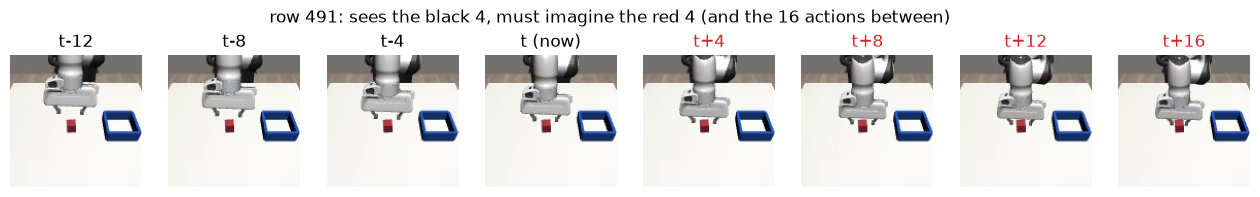

In [8]:
top, wrist = load_images()
rows = list(map(int, np.concatenate([past[t], future[t]])))  # 4 seen, 4 to imagine
names = ['t-12', 't-8', 't-4', 't (now)', 't+4', 't+8', 't+12', 't+16']
fig = plt.figure(figsize=(16, 2.3))
for i, (row, name) in enumerate(zip(rows, names)):
    ax = fig.add_subplot(1, 8, i + 1)
    ax.imshow(np.transpose(top[row], (1, 2, 0)))
    ax.set_title(name, color='tab:red' if '+' in name else 'k')
    ax.axis('off')
fig.suptitle(f'row {t}: sees the black 4, must imagine the red 4 (and the 16 actions between)')
plt.show()

### step 3 — a frame becomes a grid of tokens, not one vector

Our stand-in for UVA's frozen VAE (which gives a 16×16 grid): 4 stride-2 convs, 128 px → 8×8, one 128-d token per 16×16 px patch.


In [9]:
from torch import nn

device = 'cuda'
GRID, D = 8, 128  # 8 x 8 tokens per frame, each a D-dim vector


class Patches(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1),
            nn.GELU(),  # -> [B, 32, 64, 64]
            nn.Conv2d(32, 64, 4, 2, 1),
            nn.GELU(),  # -> [B, 64, 32, 32]
            nn.Conv2d(64, 128, 4, 2, 1),
            nn.GELU(),  # -> [B, 128, 16, 16]
            nn.Conv2d(128, D, 4, 2, 1),  # -> [B, D, 8, 8]
        )

    def forward(self, x: Tensor) -> Tensor:
        # x: [B, 3, 128, 128] floats in [0, 1]
        # out: [B, 64, D], one token per patch, row by row
        grid: Tensor = self.conv(x)  # [B, D, 8, 8]
        return grid.flatten(2).transpose(1, 2)

tokens: (4, 64, 128)  (4 frames x 64 patches x D)


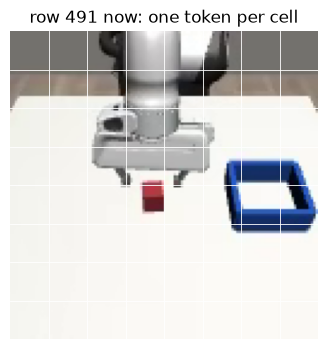

In [10]:
frames = (
    torch.tensor(top[past[t]]).to(device).float() / 255
)  # row t's 4 seen frames, [4, 3, 128, 128]
tokens: Tensor = Patches().to(device)(frames)  # untrained: only the shape means anything yet
print(f'tokens: {tuple(tokens.shape)}  (4 frames x 64 patches x D)')
fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot()
ax.imshow(np.transpose(top[t], (1, 2, 0)))
for k in range(1, GRID):  # patch borders, every 16 px
    ax.axhline(k * 16 - 0.5, color='w', lw=0.6)
    ax.axvline(k * 16 - 0.5, color='w', lw=0.6)
ax.set_title(f'row {t} now: one token per cell')
ax.axis('off')
plt.show()

### step 4 — a seen token = what's in its patch + **when** + **where**


In [11]:
# the pieces the model will own, built loose here to see the shapes (as act_byname step 17)
when = nn.Embedding(12 + 16 + 1, D).to(device)  # learned, one row per step offset -12 .. +16
where = nn.Embedding(GRID * GRID, D).to(device)  # learned, one row per patch
past_t = torch.tensor([-12, -8, -4, 0], device=device) + 12  # offsets -> rows of `when`

grids: Tensor = Patches().to(device)(frames)  # [4, 64, D], what is in each patch (step 3)
frame_when: Tensor = when(past_t)[:, None]  # [4, 1, D], one per frame, same for its 64 patches
seen_tok = grids + frame_when + where.weight  # [4, 64, D]: + which frame + which patch
print(
    tuple(grids.shape),
    '+',
    tuple(frame_when.shape),
    '+',
    tuple(where.weight.shape),
    '->',
    tuple(seen_tok.shape),
)

(4, 64, 128) + (4, 1, 128) + (64, 128) -> (4, 64, 128)


### step 5 — a future slot = one learned **unknown** + when + where

Every future slot starts as the same vector; only its when and where differ. It is a question: _what is at this patch at this step?_


In [12]:
unknown = nn.Parameter(torch.zeros(D, device=device))  # learned, shared by every future slot
future_t = torch.tensor([4, 8, 12, 16], device=device) + 12
future_tok: Tensor = unknown + when(future_t)[:, None] + where.weight  # [4, 64, D]
print(tuple(future_tok.shape), '= 4 future frames x 64 patches, nothing seen in them')

(4, 64, 128) = 4 future frames x 64 patches, nothing seen in them


### step 6 — the action slots, and the joints as one token


In [13]:
act = nn.Parameter(torch.zeros(D, device=device))  # learned, shared by every action slot
act_tok: Tensor = act + when(torch.arange(16, device=device) + 12)  # [16, D]: steps t .. t+15
joints_in = nn.Linear(8, D).to(device)  # the arm's 8 readings -> one D-wide token
now_tok: Tensor = joints_in(torch.tensor(state[t], device=device)) + when.weight[12]  # [D], at t
print(tuple(act_tok.shape), tuple(now_tok.shape))

(16, 128) (128,)


### step 7 — one sequence; a **role** tag says which kind each token is


In [14]:
role = nn.Embedding(4, D).to(device)  # learned: seen, future, action, joints
parts = [
    seen_tok.flatten(0, 1) + role.weight[0],  # [256, D]
    future_tok.flatten(0, 1) + role.weight[1],  # [256, D]
    act_tok + role.weight[2],  # [16, D]
    (now_tok + role.weight[3])[None],  # [1, D]
]
seq = torch.cat(parts)  # [529, D]
print([tuple(x.shape) for x in parts], '->', tuple(seq.shape))

[(256, 128), (256, 128), (16, 128), (1, 128)] -> (529, 128)


### step 8 — the transformer: every token reads every other

After it, the future slots and action slots hold answers; the heads in the next steps read them out.


In [15]:
layer = nn.TransformerEncoderLayer(D, 4, 4 * D, 0.0, 'gelu', batch_first=True, norm_first=True)
body = nn.TransformerEncoder(layer, 4, enable_nested_tensor=False).to(device)  # 4 layers, 4 heads
out: Tensor = body(seq[None])  # [1, 529, D]
print(f'{tuple(out.shape)}: future answers out[:, 256:512], action answers out[:, 512:528]')

(1, 529, 128): future answers out[:, 256:512], action answers out[:, 512:528]


### step 9 — the same, packed into `Board` (what training uses)

Steps 4–8 in one module, batched. `future_steps` is the knob: how many frames ahead it imagines.


In [16]:
class Board(nn.Module):
    def __init__(self, future_steps: list[int], layers: int = 4):
        super().__init__()
        self.past_t = torch.tensor([-12, -8, -4, 0]) + 12  # step offsets -> rows of `when`
        self.future_t = torch.tensor(future_steps) + 12
        self.patches = Patches()
        self.joints = nn.Linear(8, D)
        self.unknown = nn.Parameter(torch.zeros(D))  # every future slot starts as this
        self.act = nn.Parameter(torch.zeros(D))  # every action slot starts as this
        self.when = nn.Embedding(12 + 16 + 1, D)  # step offset -12 .. +16
        self.where = nn.Embedding(GRID * GRID, D)  # which patch
        self.role = nn.Embedding(4, D)  # past, future, action, joints
        layer = nn.TransformerEncoderLayer(
            D, 4, 4 * D, 0.0, 'gelu', batch_first=True, norm_first=True
        )
        self.body = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)

    def forward(self, past: Tensor, joints: Tensor) -> Tensor:
        # past: [B, 4, 3, 128, 128] in [0, 1];  joints: [B, 8] radians, now
        # out: [B, 4*64 + F*64 + 16 + 1, D], every token after reading the whole board
        B, dv = past.shape[0], past.device
        where, role = self.where.weight, self.role.weight  # [64, D], [4, D]
        grids: Tensor = self.patches(past.flatten(0, 1))  # [B*4, 64, D]
        seen: Tensor = grids.unflatten(0, (B, 4))  # [B, 4, 64, D]
        seen = seen + self.when(self.past_t.to(dv))[:, None] + where + role[0]
        future: Tensor = (
            self.unknown + self.when(self.future_t.to(dv))[:, None] + where + role[1]
        )  # [F, 64, D]
        act: Tensor = self.act + self.when(torch.arange(16, device=dv) + 12) + role[2]  # [16, D]
        now: Tensor = self.joints(joints) + self.when.weight[12] + role[3]  # [B, D]
        x = torch.cat(
            [
                seen.flatten(1, 2),
                future.flatten(0, 1).expand(B, -1, -1),
                act.expand(B, -1, -1),
                now[:, None],
            ],
            dim=1,
        )
        out: Tensor = self.body(x)
        return out

In [17]:
board = Board(future_steps=[4, 8, 12, 16]).to(device)
seen = torch.tensor(top[past[t]]).to(device).float()[None] / 255  # [1, 4, 3, 128, 128]
out: Tensor = board(seen, torch.tensor(state[t]).to(device)[None])
n = sum(p.numel() for p in board.parameters())
print(
    f'board {tuple(out.shape)} = 256 seen + 256 future + 16 action + 1 joints tokens;  {n / 1e6:.2f}M params'
)

board (1, 529, 128) = 256 seen + 256 future + 16 action + 1 joints tokens;  1.23M params


### step 10 — two heads read the answers out

Each action slot → its 8 numbers. Each future slot → the 16×16 px of its patch (3 × 16 × 16 = 768 numbers): pixels, not tokens, because we have no frozen VAE to give a fixed target.


In [18]:
to_action = nn.Linear(D, 8).to(device)  # one action slot -> one action
to_pixels = nn.Linear(D, 3 * 16 * 16).to(device)  # one future slot -> its patch, RGB
acts: Tensor = to_action(out[:, 512:528])  # [1, 16, 8], the chunk
pix: Tensor = to_pixels(out[:, 256:512])  # [1, 256, 768], 4 frames x 64 patches
print(f'actions {tuple(acts.shape)}  pixels {tuple(pix.shape)}')

actions (1, 16, 8)  pixels (1, 256, 768)


### step 11 — 256 patches back into 4 frames, next to the true ones

Untrained, so noise. The check: cutting the true frames into patches (`F.unfold`) and back gives them exactly, so the patch order matches `Patches`.


unfold -> unpatch gives the frames back: True


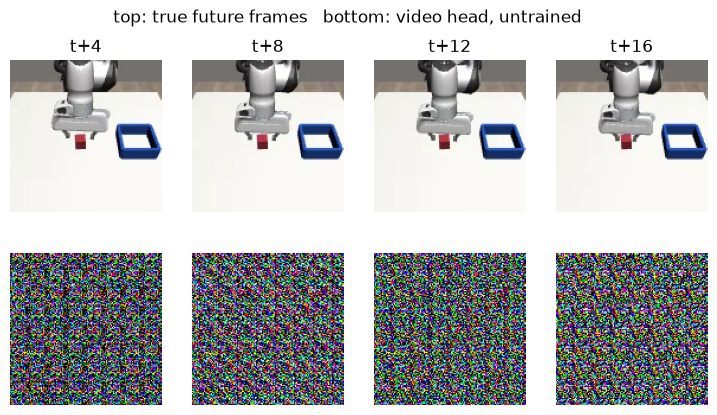

In [19]:
import torch.nn.functional as F
from einops import rearrange


def unpatch(pix: Tensor) -> Tensor:
    # [B, F*64, 768] -> [B, F, 3, 128, 128]: each slot's 768 numbers back to its 16 x 16 patch
    return rearrange(pix, 'b (f h w) (c p q) -> b f c (h p) (w q)', h=GRID, w=GRID, c=3, p=16)


truth = torch.tensor(top[future[t]]).to(device).float() / 255  # [4, 3, 128, 128], t+4 .. t+16
cut = F.unfold(truth, 16, stride=16).transpose(1, 2).flatten(0, 1)[None]  # [1, 256, 768]
print('unfold -> unpatch gives the frames back:', torch.equal(unpatch(cut)[0], truth))

guess = unpatch(pix)[0].clamp(0, 1).detach().cpu().numpy()  # [4, 3, 128, 128]
fig, axs = plt.subplots(2, 4, figsize=(9, 4.6))
for i, name in enumerate(['t+4', 't+8', 't+12', 't+16']):
    axs[0, i].imshow(np.transpose(top[future[t, i]], (1, 2, 0)))
    axs[1, i].imshow(np.transpose(guess[i], (1, 2, 0)))
    axs[0, i].set_title(name)
for ax in axs.flat:
    ax.axis('off')
fig.suptitle('top: true future frames   bottom: video head, untrained')
plt.show()

### step 12 — the loss: L1 on the chunk (as ACT) + MSE on the future pixels

The bar for the pixels: "nothing moves", the current frame copied 4 times.


In [20]:
a_std = torch.tensor(action[~is_val].std(0), device=device)  # [8], train demos only, as act step 4
real = chunk == np.arange(len(episode))[:, None] + np.arange(
    16
)  # [N, 16], False past the demo's end


def uva_loss(acts: Tensor, pix: Tensor, rows: NDArray[np.int64]) -> tuple[Tensor, Tensor]:
    # acts: [B, 16, 8] radians;  pix: [B, 4*64, 768];  rows: [B], which dataset rows
    # out: action L1 in std units over real steps (act step 7), pixel MSE over the 4 future frames
    want = torch.tensor(action[chunk[rows]], device=device)  # [B, 16, 8]
    keep = torch.tensor(real[rows], device=device)[..., None].float()  # [B, 16, 1]
    act_l1 = (((acts - want) / a_std).abs() * keep).sum() / (keep.sum() * 8)
    frames = torch.tensor(top[future[rows]], device=device).float() / 255  # [B, 4, 3, 128, 128]
    return act_l1, F.mse_loss(unpatch(pix), frames)


act_l1, pix_mse = uva_loss(acts, pix, np.array([t]))
now = torch.tensor(top[t], device=device).float() / 255  # [3, 128, 128]
copy_mse = F.mse_loss(now.expand_as(truth), truth)  # "nothing moves"
print(
    f'untrained: action L1 {act_l1:.3f} std   pixel MSE {pix_mse:.4f}   copy-now MSE {copy_mse:.4f}'
)

untrained: action L1 11.443 std   pixel MSE 1.9717   copy-now MSE 0.0125


### step 13 — `UVA`: Board + the two heads, normalised in and out (as ACT's `ChunkNet`)

Images and joints are standardised going in; both heads answer in std units and are scaled back out, so an untrained net starts near 1 std, not 13.


In [21]:
tr_rows = np.flatnonzero(~is_val)
sub = torch.tensor(top[tr_rows[::20]], device=device).float() / 255  # every 20th train frame
im_mean, im_std = sub.mean((0, 2, 3)), sub.std((0, 2, 3))  # [3] each, per colour
s_mean = torch.tensor(state[tr_rows].mean(0), device=device)  # [8]
s_std = torch.tensor(state[tr_rows].std(0), device=device)
a_mean = torch.tensor(action[tr_rows].mean(0), device=device)  # [8]; a_std is step 12's
px_mean, px_std = (
    im_mean.repeat_interleave(256),
    im_std.repeat_interleave(256),
)  # [768], a patch is RGB-major


class UVA(nn.Module):
    def __init__(self, future_steps: tuple[int, ...] = (4, 8, 12, 16), history: bool = True):
        super().__init__()
        self.history = history  # False: all 4 frame slots get the frame seen now (step 22)
        self.board = Board(list(future_steps))
        self.to_action = nn.Linear(D, 8)  # step 10's heads
        self.to_pixels = nn.Linear(D, 3 * 16 * 16)
        # where the future slots end and the action slots begin
        self.end = 256 + 64 * len(future_steps)

    def forward(self, past: Tensor, joints: Tensor) -> tuple[Tensor, Tensor]:
        # past: [B, 4, 3, 128, 128] in [0, 1];  joints: [B, 8] radians
        # out: chunk [B, 16, 8] radians;  future patches [B, F*64, 768] in [0, 1]
        if not self.history:
            past = past[:, -1:].expand_as(past)  # [B, 4, 3, 128, 128], now 4 times
        past = (past - im_mean[:, None, None]) / im_std[:, None, None]
        out = self.board(past, (joints - s_mean) / s_std)
        acts = self.to_action(out[:, self.end : self.end + 16]) * a_std + a_mean
        pix = self.to_pixels(out[:, 256 : self.end]) * px_std + px_mean
        return acts, pix

In [22]:
torch.manual_seed(0)
uva = UVA().to(device)
acts, pix = uva(seen, torch.tensor(state[t], device=device)[None])  # row 491, as step 9
act_l1, pix_mse = uva_loss(acts, pix, np.array([t]))
print(
    f'untrained: action L1 {act_l1:.3f} std   pixel MSE {pix_mse:.4f}   copy-now MSE {copy_mse:.4f}'
)

untrained: action L1 1.190 std   pixel MSE 0.1690   copy-now MSE 0.0125


### step 14 — batches on the GPU, and what one training step costs

The data goes to the GPU once (~0.3 GB), so a batch is indexing only. `batch_loss` must agree with step 12's `uva_loss`.


In [23]:
TOP = torch.tensor(top, device=device)  # [N, 3, 128, 128] uint8
STATE, ACTION = (
    torch.tensor(state, device=device),
    torch.tensor(action, device=device),
)  # [N, 8] each
PAST, FUTURE, CHUNK = (
    torch.tensor(r, device=device) for r in (past, future, chunk)
)  # rows of rows
REAL = torch.tensor(real, device=device)  # [N, 16] bool
TRAIN = torch.tensor(tr_rows, device=device)  # [Ntr]


def batch_loss(net: UVA, rows: Tensor) -> tuple[Tensor, Tensor]:
    # rows: [B] dataset rows, on the GPU
    # out: action L1 (std units, real steps only) and pixel MSE, as uva_loss
    acts, pix = net(TOP[PAST[rows]].float() / 255, STATE[rows])  # [B, 16, 8], [B, 256, 768]
    keep = REAL[rows][..., None].float()  # [B, 16, 1]
    act_l1 = (((acts - ACTION[CHUNK[rows]]) / a_std).abs() * keep).sum() / (keep.sum() * 8)
    return act_l1, F.mse_loss(unpatch(pix), TOP[FUTURE[rows]].float() / 255)

In [24]:
import time

print(
    'row 491, GPU vs step 12:',
    [f'{x:.4f}' for x in batch_loss(uva, torch.tensor([t], device=device))],
)
rows = TRAIN[torch.randint(0, len(TRAIN), (64,), device=device)]  # [64], a random train batch
for i in range(11):  # the first is warm-up
    if i == 1:
        torch.cuda.synchronize()
        t0 = time.perf_counter()
    act_l1, pix_mse = batch_loss(uva, rows)
    (act_l1 + pix_mse).backward()
torch.cuda.synchronize()
print(f'batch 64: one forward + backward {(time.perf_counter() - t0) / 10 * 1000:.0f} ms')

row 491, GPU vs step 12: ['1.1903', '0.1690']
batch 64: one forward + backward 181 ms


### step 15 — bf16 autocast: same losses, faster step?

Matmuls and convs in bfloat16, weights and the loss sums stay float32.


In [25]:
def time_step(amp: bool) -> tuple[float, Tensor, Tensor]:
    # out: ms per forward + backward on step 14's batch, and its two losses
    for i in range(11):  # the first is warm-up
        if i == 1:
            torch.cuda.synchronize()
            t0 = time.perf_counter()
        with torch.autocast('cuda', dtype=torch.bfloat16, enabled=amp):
            act_l1, pix_mse = batch_loss(uva, rows)
        (act_l1 + pix_mse).backward()
    torch.cuda.synchronize()
    return (time.perf_counter() - t0) / 10 * 1000, act_l1, pix_mse


for amp in (False, True):
    ms, act_l1, pix_mse = time_step(amp)
    print(
        f'{"bf16" if amp else "fp32"}: {ms:4.0f} ms   action L1 {act_l1:.4f}   pixel MSE {pix_mse:.4f}'
    )

fp32:  178 ms   action L1 1.2933   pixel MSE 0.1754
bf16:   70 ms   action L1 1.2934   pixel MSE 0.1754


### step 16 — train `UVA` (~4 min): loss = action L1 + pixel MSE

Every 500 steps: val error of each chunk's first action (radians, as ACT) and val pixel MSE against the copy-now bar. No random shift yet.


In [26]:
VAL = torch.tensor(np.flatnonzero(is_val), device=device)  # [Nva]


@torch.no_grad()
def val_metrics(net: UVA) -> tuple[Tensor, float]:
    # out: [8] mean |error| of each val chunk's first action, radians;  pixel MSE over the 4 future frames
    errs, sq = [], 0.0
    for j in range(0, len(VAL), 256):
        rows = VAL[j : j + 256]
        with torch.autocast('cuda', dtype=torch.bfloat16):
            acts, pix = net(TOP[PAST[rows]].float() / 255, STATE[rows])
        errs.append((acts[:, 0].float() - ACTION[rows]).abs())  # [b, 8]
        sq += ((unpatch(pix.float()) - TOP[FUTURE[rows]].float() / 255) ** 2).sum().item()
    return torch.cat(errs).mean(0), sq / (len(VAL) * 4 * 3 * 128 * 128)


# the bar on val: every future frame guessed as the frame seen now
copy_val = sum(
    ((TOP[PAST[r, -1]][:, None].float() - TOP[FUTURE[r]].float()) ** 2).sum().item() / 255**2
    for r in VAL.split(256)
) / (len(VAL) * 4 * 3 * 128 * 128)
err, mse = val_metrics(uva)
print(
    f'untrained: val arm {err[:7].mean():.4f}  gripper {err[7]:.4f}  pix {mse:.4f}   copy-now {copy_val:.4f}'
)

untrained: val arm 0.1462  gripper 0.3951  pix 0.1772   copy-now 0.0128


In [27]:
@cache
def train(
    seed: int = 0, steps: int = 3000, lr: float = 1e-3, pix_w: float = 1.0, history: bool = True
) -> dict[str, Tensor]:
    # pix_w: weight of the video loss; 0 trains the action half alone. history: False sees now only
    torch.manual_seed(seed)
    net = UVA(history=history).to(device)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    for step in range(steps + 1):
        rows = TRAIN[torch.randint(0, len(TRAIN), (64,), device=device)]  # [64]
        with torch.autocast('cuda', dtype=torch.bfloat16):  # step 15
            act_l1, pix_mse = batch_loss(net, rows)
        opt.zero_grad()
        (act_l1 + pix_w * pix_mse).backward()
        opt.step()
        if step % 500 == 0:
            err, mse = val_metrics(net)
            print(
                f'{step:5d}  train act {act_l1.item():.4f} pix {pix_mse.item():.4f}'
                f'   val arm {err[:7].mean():.4f}  gripper {err[7]:.4f}  pix {mse:.4f}'
            )
    # weights on the CPU, so the cache holds no GPU tensors
    return {k: v.cpu() for k, v in net.state_dict().items()}

train: not cached, will compute


In [28]:
uva = UVA().to(device)
uva.load_state_dict(train())
print(f'copy-now bar for val pix: {copy_val:.4f}')

    0  train act 1.2934 pix 0.1754   val arm 0.1382  gripper 0.6085  pix 0.1613
  500  train act 0.0870 pix 0.0128   val arm 0.0104  gripper 0.0764  pix 0.0134
 1000  train act 0.0516 pix 0.0111   val arm 0.0087  gripper 0.0428  pix 0.0112
 1500  train act 0.0420 pix 0.0099   val arm 0.0068  gripper 0.0292  pix 0.0099
 2000  train act 0.0374 pix 0.0086   val arm 0.0072  gripper 0.0242  pix 0.0089
 2500  train act 0.0373 pix 0.0080   val arm 0.0064  gripper 0.0252  pix 0.0081
 3000  train act 0.0329 pix 0.0071   val arm 0.0062  gripper 0.0237  pix 0.0075
copy-now bar for val pix: 0.0128


### step 17 — what it imagines: val demo 19 at two moments

Per moment: the true frames on top, the video head's below; the first column is the frame it sees now.


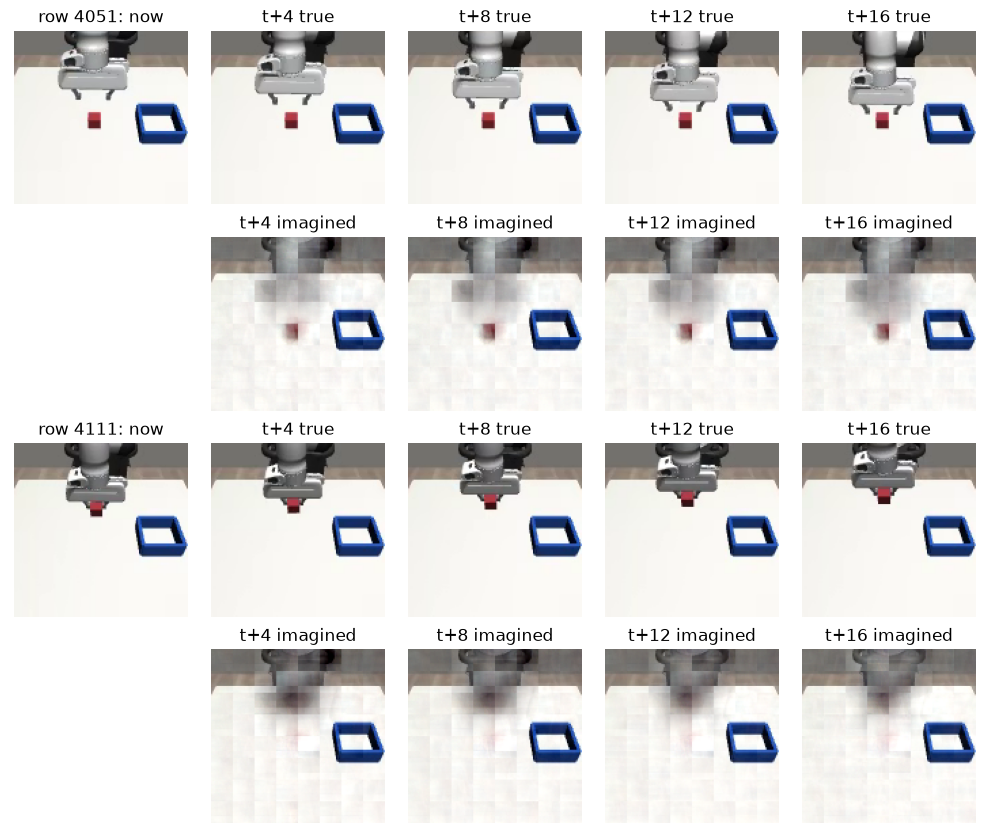

In [29]:
moments = [int(np.flatnonzero(episode == 19)[s]) for s in (40, 100)]  # a held-out demo
with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
    _, pix = uva(TOP[PAST[moments]].float() / 255, STATE[moments])
guess = unpatch(pix.float()).clamp(0, 1).cpu().numpy()  # [2, 4, 3, 128, 128]
fig, axs = plt.subplots(4, 5, figsize=(10, 8.4))
for m, row in enumerate(moments):
    axs[2 * m, 0].imshow(np.transpose(top[row], (1, 2, 0)))
    axs[2 * m, 0].set_title(f'row {row}: now')
    for i, name in enumerate(['t+4', 't+8', 't+12', 't+16']):
        axs[2 * m, i + 1].imshow(np.transpose(top[future[row, i]], (1, 2, 0)))
        axs[2 * m + 1, i + 1].imshow(np.transpose(guess[m, i], (1, 2, 0)))
        axs[2 * m, i + 1].set_title(f'{name} true')
        axs[2 * m + 1, i + 1].set_title(f'{name} imagined')
for ax in axs.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

### step 18 — the sim, and `predict(seen, obs)`: the frame history in, a chunk out

New vs ACT: it needs the frames 4, 8, 12 steps back, so the caller keeps every top frame since reset. Before step 12 the first frame stands in, as `rows_at` clipped in training.


In [30]:
import logging
import os

os.environ.setdefault(
    'MUJOCO_GL', 'egl'
)  # render without a window; must be set before mujoco loads
logging.disable(logging.WARNING)  # robosuite warns while importing; mute that
import robosuite  # noqa: E402, F401

logging.disable(logging.NOTSET)
logging.getLogger('robosuite_logs').setLevel(logging.ERROR)

from dream_robot.core.registry import make_env  # noqa: E402

env = make_env('robosuite/pick_place_cube')  # as act step 9


@torch.no_grad()
def predict(seen: list[np.ndarray], obs) -> np.ndarray:
    # seen: every top frame since reset, [H, W, 3] uint8 each, newest last
    # out: [16, 8], the chunk from now
    now = len(seen) - 1
    ims = np.stack([seen[max(0, now + o)] for o in (-12, -8, -4, 0)])  # [4, H, W, 3]
    past = (
        torch.from_numpy(ims).permute(0, 3, 1, 2)[None].to(device).float() / 255
    )  # [1, 4, 3, H, W]
    with torch.autocast('cuda', dtype=torch.bfloat16):
        acts, _ = uva(past, torch.from_numpy(obs.state)[None].to(device))  # the pixels go unused
    chunk = acts[0].float().cpu().numpy()  # [16, 8]
    chunk[:, 7] = np.clip(chunk[:, 7], 0.0, 1.0)  # gripper commands must stay in [0, 1]
    return chunk


uva.eval()
obs = env.reset(seed=1000)
print(predict([obs.images['top']], obs)[:3])  # the first 3 actions of the first chunk

[[ 0.048  0.267 -0.025 -2.56  -0.01   3.015  0.815  1.   ]
 [ 0.048  0.278 -0.025 -2.551 -0.01   3.011  0.815  1.   ]
 [ 0.049  0.29  -0.025 -2.541 -0.012  3.014  0.818  1.   ]]


### step 19 — play the chunk: n actions blind, then re-plan (as act step 10)


In [31]:
def rollout(seed: int, n_exec: int) -> tuple[bool, str, int]:
    # predict a chunk, play its first n_exec actions without looking, then predict again;
    # every top frame is kept, so predict can look 4, 8, 12 steps back
    # out: (success, failure mode, steps taken)
    obs = env.reset(seed=seed)
    seen = [obs.images['top']]
    plan = []  # actions still to play from the last chunk
    for step in range(600):
        if not plan:
            plan = list(predict(seen, obs)[:n_exec])  # n_exec x [8]
        r = env.step(plan.pop(0))
        obs = r.observation
        seen.append(obs.images['top'])
        if r.terminated or r.truncated:
            break
    return r.success, str(r.failure_mode), step + 1


t0 = time.perf_counter()
ok, mode, steps = rollout(1000, n_exec=8)  # UVA's own setting: 8 of 16
print(
    f'seed 1000: {"SUCCESS" if ok else mode}  after {steps} steps  ({time.perf_counter() - t0:.1f} s)'
)

seed 1000: SUCCESS  after 208 steps  (0.9 s)


### step 20 — how many steps to play blind? 20 seeds each (~2 min)

Same 20 unseen seeds as act step 11 (ACT's 50-step chunk: 0, 5, 9, 18, 16 of 20 at n_exec 1, 5, 10, 25, 50).


In [32]:
from collections import Counter

sweep = {}  # n_exec -> {seed: (success, failure mode, steps)}
for n_exec in [1, 4, 8, 16]:
    sweep[n_exec] = {seed: rollout(seed, n_exec) for seed in range(1000, 1020)}
    res = sweep[n_exec].values()
    wins = sum(ok for ok, _, _ in res)
    fails = Counter(mode for ok, mode, _ in res if not ok)
    print(f'n_exec {n_exec:2d}: {wins:2d}/20   failures {dict(fails)}')

n_exec  1: 20/20   failures {}
n_exec  4: 19/20   failures {'dropped': 1}
n_exec  8: 19/20   failures {'dropped': 1}
n_exec 16: 20/20   failures {}


### step 21 — ablation: no video loss (`pix_w=0`), everything else the same (~4 min + ~2 min)

If it still goes 80/80, the video loss isn't what made step 20 work on this task. Val pix will stay bad: the pixel head never trains.


In [33]:
uva_video = uva  # step 16's net, kept
uva = UVA().to(device)  # predict and rollout read the global `uva`
uva.load_state_dict(train(pix_w=0.0))
uva.eval();

    0  train act 1.2934 pix 0.1754   val arm 0.1384  gripper 0.6115  pix 0.1768
  500  train act 0.0834 pix 0.1587   val arm 0.0111  gripper 0.0723  pix 0.1598
 1000  train act 0.0531 pix 0.1558   val arm 0.0089  gripper 0.0450  pix 0.1553
 1500  train act 0.0430 pix 0.1485   val arm 0.0072  gripper 0.0219  pix 0.1519
 2000  train act 0.0309 pix 0.1474   val arm 0.0064  gripper 0.0214  pix 0.1480
 2500  train act 0.0366 pix 0.1462   val arm 0.0067  gripper 0.0249  pix 0.1457
 3000  train act 0.0311 pix 0.1416   val arm 0.0066  gripper 0.0223  pix 0.1427


In [34]:
sweep_no_video = {}  # n_exec -> {seed: (success, failure mode, steps)}
for n_exec in [1, 4, 8, 16]:
    sweep_no_video[n_exec] = {seed: rollout(seed, n_exec) for seed in range(1000, 1020)}
    res = sweep_no_video[n_exec].values()
    fails = Counter(mode for ok, mode, _ in res if not ok)
    print(
        f'n_exec {n_exec:2d}: {sum(ok for ok, _, _ in res):2d}/20   failures {dict(fails)}   (with video: 20/20)'
    )

n_exec  1: 14/20   failures {'no_grasp': 4, 'dropped': 2}   (with video: 20/20)
n_exec  4: 15/20   failures {'no_grasp': 4, 'wrong_target': 1}   (with video: 20/20)
n_exec  8: 15/20   failures {'no_grasp': 4, 'dropped': 1}   (with video: 20/20)
n_exec 16: 18/20   failures {'no_grasp': 1, 'dropped': 1}   (with video: 20/20)


### step 22 — ablation: no frame history (`history=False`), video loss kept (~4 min + ~2 min)

All 4 frame slots get the frame seen now, in training and at run time. If `n_exec 1` falls toward ACT's 0/20, the history is what made step 20 work.


In [35]:
uva_no_video = uva  # step 21's net, kept
uva = UVA(history=False).to(device)  # predict and rollout read the global `uva`
uva.load_state_dict(train(history=False))
uva.eval();

    0  train act 1.2935 pix 0.1754   val arm 0.1382  gripper 0.6086  pix 0.1613
  500  train act 0.0911 pix 0.0130   val arm 0.0126  gripper 0.0728  pix 0.0134
 1000  train act 0.0586 pix 0.0111   val arm 0.0085  gripper 0.0459  pix 0.0111
 1500  train act 0.0443 pix 0.0095   val arm 0.0075  gripper 0.0316  pix 0.0096
 2000  train act 0.0406 pix 0.0083   val arm 0.0065  gripper 0.0304  pix 0.0087
 2500  train act 0.0441 pix 0.0079   val arm 0.0070  gripper 0.0349  pix 0.0080
 3000  train act 0.0343 pix 0.0070   val arm 0.0068  gripper 0.0332  pix 0.0074


In [36]:
sweep_no_history = {}  # n_exec -> {seed: (success, failure mode, steps)}
for n_exec in [1, 4, 8, 16]:
    sweep_no_history[n_exec] = {seed: rollout(seed, n_exec) for seed in range(1000, 1020)}
    res = sweep_no_history[n_exec].values()
    fails = Counter(mode for ok, mode, _ in res if not ok)
    print(f'n_exec {n_exec:2d}: {sum(ok for ok, _, _ in res):2d}/20   failures {dict(fails)}')
print('with history: 20, 20, 20, 20 /20 (step 20);  no video: 18, 19, 19, 20 (step 21)')

n_exec  1: 16/20   failures {'no_grasp': 4}
n_exec  4: 18/20   failures {'no_grasp': 2}
n_exec  8: 17/20   failures {'no_grasp': 3}
n_exec 16: 18/20   failures {'no_grasp': 2}
with history: 20, 20, 20, 20 /20 (step 20);  no video: 18, 19, 19, 20 (step 21)
